## Performance analysis of the Bayesian Networks

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
from pgmpy.estimators import ExpectationMaximization
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, brier_score_loss, roc_auc_score, RocCurveDisplay
from sklearn.preprocessing import KBinsDiscretizer

#### Loading data and pre-process

In [87]:
tele = pd.read_csv("./../data/raw/telemetry.csv", parse_dates=["timestamp"])
labels = pd.read_csv("./../data/processed/labels-3.csv", parse_dates=["timestamp"])

df = tele.merge(labels, on=["timestamp", "machine_id"])
df["delta_temp"] = df["spindle_temp"] - df["ambient_temp"]

vib_hi = df["vibration_rms"].quantile(0.9)
temp_hi = df["delta_temp"].quantile(0.9)
flow_lo = df["coolant_flow"].quantile(0.1)

df["high_vibration"] = (df["vibration_rms"] > vib_hi).astype(int)
df["high_spindle_temp"] = (df["delta_temp"] > temp_hi).astype(int)
df["low_coolant_flow"] = (df["coolant_flow"] < flow_lo).astype(int)
df["spindle_overheat"] = df["spindle_overheat"].astype(int)
df.head()

,timestamp,machine_id,spindle_temp,ambient_temp,vibration_rms,coolant_flow,feed_rate,spindle_speed,load_pct,power_kw,tool_wear,spindle_overheat,delta_temp,high_vibration,high_spindle_temp,low_coolant_flow
0,2025-01-01 00:00:00,M-A,73.96,24.36,0.871,1.050,0.9,3600,0.294,3.193,0.000,0,49.60,0,0,0
1,2025-01-01 00:05:00,M-A,53.38,22.87,0.536,1.083,1.3,800,0.329,2.149,0.000,0,30.51,0,0,0
2,2025-01-01 00:10:00,M-A,58.12,24.59,0.455,1.025,0.9,1200,0.369,2.457,0.001,0,33.53,0,0,0
3,2025-01-01 00:15:00,M-A,58.08,23.05,0.680,0.977,0.7,1200,0.479,2.702,0.001,0,35.03,0,0,0
4,2025-01-01 00:20:00,M-A,55.37,24.28,0.663,1.072,1.1,800,0.328,2.148,0.001,0,31.09,0,0,0


In [88]:
df['spindle_overheat'].value_counts()

spindle_overheat
0    81031
1    22649
Name: count, dtype: int64

#### Hold-out train-test split

In order to be able to apply the conventional metrics to a Bayesian Networks (**BN**), contrary to what is done in the baysian_network notebook the model training can't be use the entire dataset. 

In [113]:
train_df, test_df = train_test_split(
    df,
    train_size=0.8,
    random_state=42,
    stratify=df['spindle_overheat']
)

print("ORGINAL LABEL DISTRIBUTION:")
for label, val in df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/df.shape[0]*100, ndigits=2)}%")
print("\n#-----------------------------------------------#\n")

print("TRAIN SET LABEL DISTRIBUTION:")
for label, val in train_df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/train_df.shape[0]*100, ndigits=2)}%")
print("\n#-----------------------------------------------#\n")

print("TEST SET LABEL DISTRIBUTION:")
for label, val in test_df['spindle_overheat'].value_counts().items():
    print(f"{label}: {round(number=val/test_df.shape[0]*100, ndigits=2)}%")

ORGINAL LABEL DISTRIBUTION:
0: 78.15%
1: 21.85%

#-----------------------------------------------#

TRAIN SET LABEL DISTRIBUTION:
0: 78.16%
1: 21.84%

#-----------------------------------------------#

TEST SET LABEL DISTRIBUTION:
0: 78.15%
1: 21.85%


In [114]:
disc = KBinsDiscretizer(n_bins=5,
                        encode='ordinal',
                        strategy='quantile',
                        quantile_method='averaged_inverted_cdf',
                        )


train_df_X = disc.fit_transform(train_df[['vibration_rms', 'delta_temp', 'coolant_flow']])
test_df_X = disc.transform(test_df[['vibration_rms', 'delta_temp', 'coolant_flow']])

In [115]:
train_labels= train_df['spindle_overheat']
test_labels= test_df['spindle_overheat']

train_df = pd.DataFrame(data=train_df_X, columns=['vibration_rms', 'delta_temp', 'coolant_flow'])
train_df['spindle_overheat']=train_labels.values

test_df = pd.DataFrame(data=test_df_X, columns=['vibration_rms', 'delta_temp', 'coolant_flow'])
test_df['spindle_overheat']=test_labels.values

In [ ]:
# for col in train_df.columns:
#     train_df[col] = train_df[col].astype(int)
#     test_df[col] = test_df[col].astype(int)
    

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

#### Training models

In [117]:
model1 = DiscreteBayesianNetwork(
    ebunch=[
        ("spindle_overheat", "vibration_rms"),
        ("spindle_overheat", "delta_temp"),
        ("spindle_overheat", "coolant_flow"),
    ],
)

model1.fit(train_df, estimator=MaximumLikelihoodEstimator)

model1.check_model()

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'vibration_rms': 'N', 'delta_temp': 'N', 'coolant_flow': 'N', 'spindle_overheat': 'N'}


True

In [118]:
infer1 = VariableElimination(model1)

q1 = infer1.query(
    variables=["spindle_overheat"],
    evidence={"vibration_rms": 1, "delta_temp": 3, "coolant_flow": 1},
)
print(q1.values)
print(q1)

[0.95668564 0.04331436]
+---------------------+-------------------------+
| spindle_overheat    |   phi(spindle_overheat) |
+=====================+=========================+
| spindle_overheat(0) |                  0.9567 |
+---------------------+-------------------------+
| spindle_overheat(1) |                  0.0433 |
+---------------------+-------------------------+


In [119]:
model2 = DiscreteBayesianNetwork(
    ebunch=[
        ("bearing_wear_high", "vibration_rms"),
        ("bearing_wear_high", "spindle_overheat"),
        ("fan_fault", "delta_temp"),
        ("fan_fault", "spindle_overheat"),
        ("clogged_filter", "coolant_flow"),
        ("clogged_filter", "spindle_overheat"),
        ("low_cooling_efficiency", "delta_temp"),
        ("low_cooling_efficiency", "spindle_overheat"),
    ],
    latents={
        "bearing_wear_high", 
        "clogged_filter", 
        "fan_fault", 
        "low_cooling_efficiency"
    },
)



em_est = ExpectationMaximization(model=model2, data=train_df)

cpds_em = em_est.get_parameters(
    latent_card={lv: 2 for lv in ["bearing_wear_high", "fan_fault", "clogged_filter", "low_cooling_efficiency"]},
    max_iter=30,
    atol=1e-8,
    n_jobs=8,
    seed=42,
    show_progress=True,
)

model2.add_cpds(*cpds_em)

model2.check_model()

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'vibration_rms': 'N', 'delta_temp': 'N', 'coolant_flow': 'N', 'spindle_overheat': 'N'}
100%|██████████| 30/30 [00:25<00:00,  1.20it/s]


True

In [121]:
infer2 = VariableElimination(model2)

evidence={
    "vibration_rms": 1.0, 
    "delta_temp": 4.0, 
    "coolant_flow": 0.
}

# 1) Overheat probability
q_overheat = infer2.query(
    variables=["spindle_overheat"],
    evidence=evidence,
)
print("P(SpindleOverheat | evidence):")
print(q_overheat)

# 2) Posterior over latent causes
q_causes = infer2.query(
    variables=["bearing_wear_high", "fan_fault", "clogged_filter", "low_cooling_efficiency"],
    evidence=evidence,
)
print("\nP(Causes | evidence):")
print(q_causes)

P(SpindleOverheat | evidence):
+---------------------+-------------------------+
| spindle_overheat    |   phi(spindle_overheat) |
+=====================+=========================+
| spindle_overheat(0) |                  0.3175 |
+---------------------+-------------------------+
| spindle_overheat(1) |                  0.6825 |
+---------------------+-------------------------+

P(Causes | evidence):
+----------------------+--------------+-------------------+---------------------------+--------------------------------------------------------------------------+
| bearing_wear_high    | fan_fault    | clogged_filter    | low_cooling_efficiency    |   phi(bearing_wear_high,fan_fault,clogged_filter,low_cooling_efficiency) |
+======================+==============+===================+===========================+==========================================================================+
| bearing_wear_high(0) | fan_fault(0) | clogged_filter(0) | low_cooling_efficiency(0) |                    

#### Classification metrics

In [127]:
def perdict_overheat_prob(infer, evidence):
    """
    Returns the probabilty of spindle_overheat acording to the inference algorithm passed and the evidence
    """
    res = infer.query(
        variables=["spindle_overheat"],
        evidence=evidence,
        show_progress=False,
    )

    return res.values

In [128]:
def find_neighbours(value, df, colname):
    differences = np.abs(df[colname] - value)
    nearest_index = differences.argsort()[0]

    return df[colname].iloc[nearest_index]

In [124]:
test_df[test_df['vibration_rms']==1].iloc[0]['vibration_rms']

np.float64(1.0)

Iterate over the test set and get probabilities of the positive class and true class according to each BN

In [132]:
y_true = []
y_prob_m1 = []
y_prob_m2 = []
log_prob_m1 = []
log_prob_m2 = []

# geting predictions
for _, row in test_df.iterrows():
    evidence = {
        "vibration_rms": row["vibration_rms"],
        "delta_temp": row["delta_temp"],
        "coolant_flow": row["coolant_flow"],
    }


    true_label = row["spindle_overheat"]

    y_true.append(row["spindle_overheat"])
    y_prob_m1.append(perdict_overheat_prob(infer=infer1, evidence=evidence)[1])
    y_prob_m2.append(perdict_overheat_prob(infer=infer2, evidence=evidence)[1])
    log_prob_m1.append(np.log(perdict_overheat_prob(infer=infer1, evidence=evidence)[int(true_label)]))
    log_prob_m2.append(np.log(perdict_overheat_prob(infer=infer2, evidence=evidence)[int(true_label)]))


Some functions such as `classfication_report` and `confusion_matrix`, can't handle the probabilities instead they use hard labels

In [133]:
#transforming the probabilities of spindle overheat (positive class) in hard labels
y_pred_m1 = (np.array(y_prob_m1)>=0.5).astype(int)
y_pred_m2 = (np.array(y_prob_m2)>=0.5).astype(int)

##### Model 1 (BN with the Maximum Likelihood Estimator)

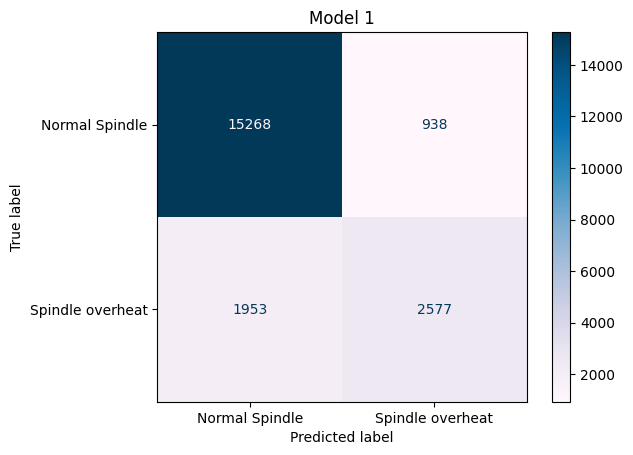

                  precision    recall  f1-score   support

  Normal Spindle       0.89      0.94      0.91     16206
Spindle overheat       0.73      0.57      0.64      4530

        accuracy                           0.86     20736
       macro avg       0.81      0.76      0.78     20736
    weighted avg       0.85      0.86      0.85     20736


#-----------------------------------------------#

Brier loss score: 0.10294493703138556
Meadian predictive log probability: -0.0398080864630974
Sum predictive log probability: -6533.392917534424

#-----------------------------------------------#



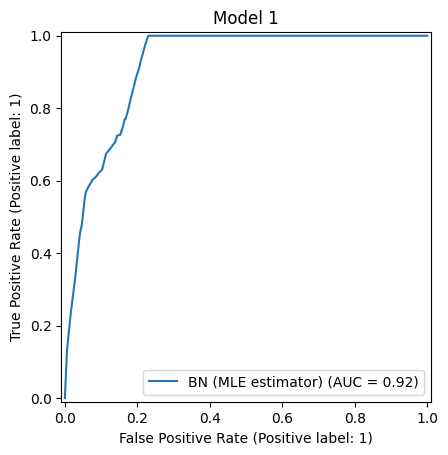

ROC-AUC: 0.9175205392274248


In [134]:
cm = confusion_matrix(y_true=y_true, y_pred=y_pred_m1)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels= ["Normal Spindle","Spindle overheat"]
)
disp.plot(
    cmap="PuBu",
    )

plt.title("Model 1")
plt.show()

print(classification_report(y_true=y_true, y_pred=y_pred_m1, target_names=["Normal Spindle","Spindle overheat"]))
print("\n#-----------------------------------------------#\n")


brier = brier_score_loss(y_true=y_true, y_proba=y_prob_m1)
print(f"Brier loss score: {brier}")
print(f"Meadian predictive log probability: {np.median(log_prob_m1)}")
# Using the sum is only possible since the test set is the exact same for both models
print(f"Sum predictive log probability: {np.sum(log_prob_m1)}")


print("\n#-----------------------------------------------#\n")

RocCurveDisplay.from_predictions(y_true=y_true, y_score=y_prob_m1, name="BN (MLE estimator)")
plt.title("Model 1")
plt.show()

roc_auc = roc_auc_score(y_true=y_true, y_score=y_prob_m1)
print(f"ROC-AUC: {roc_auc}")

The model has perfect f1-score, and the confusion matrix confirms that when using hard labels the models never miss classifies. As such the more important metrics are Brier loss score and median predictive log probability, since they can measure the BN performance according to probability inferered.

Brier loss score measures the sqared diference between the predicted probability and the actual outcome, this makes it a good calibration metric since the impact of a single prediction to the metric is limited between [0,1] in binary classification cases.

$$
\frac{1}{N} \sum_{i=1}^{N} \left( y_i - \hat{p}_i \right)^2
$$

where $y_i$ is the binary target and $\hat{p}_i$
is the predicted probability of the positive class.


The predictive log probability is the log of the probability the BN predicted to the correct class, this penalizes heavily confidence mistakes. 
The combination of Brier loss score and predictive log probability provides a more complete assessment of probabilistic decision quality.

##### Model 2 (BN with the Expectation Maximization)

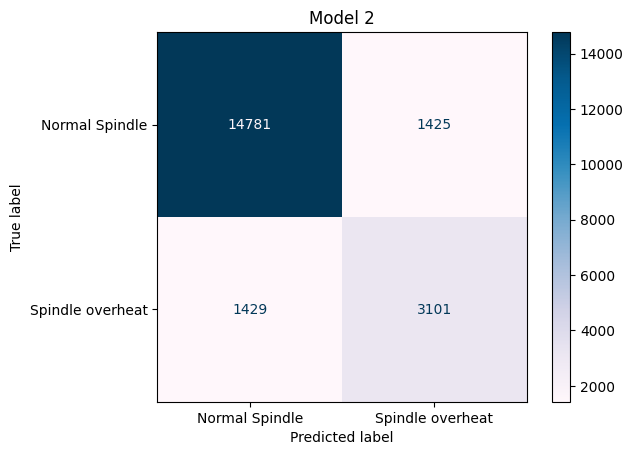

                  precision    recall  f1-score   support

  Normal Spindle       0.91      0.91      0.91     16206
Spindle overheat       0.69      0.68      0.68      4530

        accuracy                           0.86     20736
       macro avg       0.80      0.80      0.80     20736
    weighted avg       0.86      0.86      0.86     20736


#-----------------------------------------------#

Brier loss score: 0.0844908087035244
Median predictive log probability: -0.02828328149381675
Sum predictive log probability: -5209.603518187956

#-----------------------------------------------#



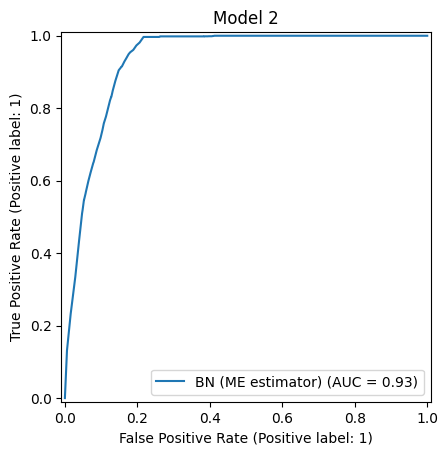

ROC-AUC: 0.9344159522854071


In [135]:
cm = confusion_matrix(y_true=y_true, y_pred=y_pred_m2)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels= ["Normal Spindle","Spindle overheat"]
)
disp.plot(
    cmap="PuBu",
    )

plt.title("Model 2")
plt.show()

print(classification_report(y_true=y_true, y_pred=y_pred_m2, target_names=["Normal Spindle","Spindle overheat"]))
print("\n#-----------------------------------------------#\n")


brier = brier_score_loss(y_true=y_true, y_proba=y_prob_m2)
print(f"Brier loss score: {brier}")
print(f"Median predictive log probability: {np.median(log_prob_m2)}")
# Using the sum is only possible since the test set is the exact same for both models
print(f"Sum predictive log probability: {np.sum(log_prob_m2)}")

print("\n#-----------------------------------------------#\n")

RocCurveDisplay.from_predictions(y_true=y_true, y_score=y_prob_m2, name="BN (ME estimator)")
plt.title("Model 2")
plt.show()

roc_auc = roc_auc_score(y_true=y_true, y_score=y_prob_m2)
print(f"ROC-AUC: {roc_auc}")

Model 2 also has perfect f1 score, so the only way to compare both models is to use the Brier loss score and the predictive log probability, these metrics show that the Model 2 seems to be much more confident in its predictions, they are orders of magnitude smaller than in Model 1, this might imply that Model 2 is slightly better, however when calculating the diference in confidence on the median predictive log probability it is 4.3% in the probability inferred. Also Model 2 lowest probability for the correct class was 98% while for Model 1 was 95.6%.